# GPE imaginary-time GPU benchmark

Open this notebook in Colab, select **Runtime → Change runtime type → GPU**, and run
the cells in order in a fresh runtime. The source is copied from
`MyDrive/GPE_simulator/gpe`, so local Drive changes can be tested without a Git push.

Defaults: **1024³**, complex128, **200 imaginary-time steps**, scalars every **50**
steps, and spectrum/TOF/density plots every **200** steps. The first 5 steps warm up
the solver; the next 5 measure individual stages; the remaining steps benchmark
the existing `imaginary_step` function. All 200 steps contribute to the final state.

Only the **final** wavefunction is saved, as `psi_final.npy`, and copied to Drive
with the benchmark results. There are no initial or periodic wavefunction saves.
This is a performance run, not a ground-state convergence claim.

At 1024³, three complex128 states plus the real potential occupy **56 GiB**, before
FFT workspace. The memory check adds an estimated 8 GiB reserve; actual requirements
can be higher. The final NPY file is **16 GiB**. GPU availability varies in
[Colab](https://research.google.com/colaboratory/faq.html#resource-limits);
the notebook stops if the selected size cannot pass the memory check and never
silently lowers N.


In [1]:
import importlib.util
import subprocess
import sys

subprocess.run(["nvidia-smi"],check=True)
if importlib.util.find_spec("cupy") is None:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","cupy-cuda12x[ctk]"])

import cupy as cp
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import json
import shutil
import time

cp.cuda.Device(0).use()
properties=cp.cuda.runtime.getDeviceProperties(0)
gpu_name=properties['name']
if isinstance(gpu_name,bytes):
    gpu_name=gpu_name.decode()
print(f"GPU: {gpu_name} | CuPy: {cp.__version__}")
print(f"CUDA runtime: {cp.cuda.runtime.runtimeGetVersion()} | driver: {cp.cuda.runtime.driverGetVersion()}")


GPU: NVIDIA A100-SXM4-80GB | CuPy: 14.0.1
CUDA runtime: 13000 | driver: 13000


## Load the current source from Drive

Change `DRIVE_PROJECT` only if your folder has a different name. Let Google Drive
finish syncing the updated `gpe` files first. Computation and initial file writes
use Colab's local disk; the final results are then copied to Drive.


In [2]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_PROJECT=Path("/content/drive/MyDrive/GPE_simulator")
LOCAL_PROJECT=Path("/content/GPE_simulator")
shutil.copytree(DRIVE_PROJECT/"gpe",LOCAL_PROJECT/"gpe",dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("__pycache__"))
sys.path.insert(0,str(LOCAL_PROJECT))

from gpe import config
from gpe.grids import get_grids
from gpe.initial_states import gaussian
from gpe.potentials import box_potential
from gpe.propagation import imaginary_step
from gpe.kernels import imag_static_real_halfstep, imag_kinetic_full_step
from gpe.helper import normalise, get_beta, get_N, get_E, get_L, is_due
from gpe.nk_extraction import nk_extraction
from gpe.monitor import monitor
from gpe.export import export

print(f"Loaded source from {LOCAL_PROJECT/'gpe'}")


Mounted at /content/drive
Loaded source from /content/GPE_simulator/gpe


## Run settings

The physical parameters follow `config.py`. `a` is in Bohr radii, and beta is
calculated once from `N_atom` and `a`. N in the monitor is the wavefunction norm;
E is kinetic energy and L is integrated Lz. Set any monitor interval to 0 to disable it.


In [3]:
N_grids=1024
total_steps=200
warmup_steps=5
profile_steps=5
progress_interval=10
fft_headroom_gib=8

simulation_range=config.simulation_range
R,L=config.R,config.L
wallthickness,U_D=config.wallthickness,config.U_D
img_dt=config.img_dt
N_atom,a=config.N_atom,config.a
sigma=3.0
beta=float(get_beta(N_atom,a))

monitor_intervals=dict(
    print_scalar_interval=50,
    show_nk_interval=200,
    show_TOF_image_interval=200,
    show_verticle_TOF_interval=0,
    show_TOF_slice_interval=0,
    show_verticle_TOF_slice_interval=0,
    show_magnifier_interval=0,
    show_magnifier_slice_interval=200,
    show_phase_interval=0,
)

assert 0<=warmup_steps and 0<profile_steps and warmup_steps+profile_steps<total_steps
assert N_grids>=2 and N_grids%2==0
run_id=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")+f"_N{N_grids}"
LOCAL_RUN=Path("/content/gpe_benchmarks")/run_id
DRIVE_RUN=DRIVE_PROJECT/"benchmark_results"/run_id
print(f"N={N_grids}, steps={total_steps}, dt={img_dt}, beta={beta:.8g}")
print(f"Final destination: {DRIVE_RUN}")


N=1024, steps=200, dt=0.01, beta=59848.533
Final destination: /content/drive/MyDrive/GPE_simulator/benchmark_results/20261010T095235Z_N1024


In [4]:
GiB=1024**3
free_bytes,total_bytes=cp.cuda.runtime.memGetInfo()
state_bytes=N_grids**3*np.dtype(np.complex128).itemsize
potential_bytes=N_grids**3*np.dtype(np.float64).itemsize
array_bytes=3*state_bytes+potential_bytes
estimated_bytes=array_bytes+fft_headroom_gib*GiB
print(f"GPU free / total: {free_bytes/GiB:.2f} / {total_bytes/GiB:.2f} GiB")
print(f"Main arrays: {array_bytes/GiB:.2f} GiB; with estimated FFT reserve: {estimated_bytes/GiB:.2f} GiB")
print(f"Final wavefunction on disk: {state_bytes/GiB:.2f} GiB")
if free_bytes<estimated_bytes:
    raise MemoryError(
        f"N={N_grids} needs an estimated {estimated_bytes/GiB:.1f} GiB, "
        f"but this GPU has {free_bytes/GiB:.1f} GiB free. "
        "Select a GPU with more memory or explicitly change N_grids and rerun from the settings cell.")
if shutil.disk_usage("/content").free<state_bytes+GiB:
    raise OSError("Insufficient local disk space for the final wavefunction.")


GPU free / total: 78.83 / 79.25 GiB
Main arrays: 56.00 GiB; with estimated FFT reserve: 64.00 GiB
Final wavefunction on disk: 16.00 GiB


## Timing and a small kernel check

The profiling wrapper below performs the same operations as `imaginary_step`,
with CUDA events around each stage. A 16³ check compares the two implementations
before the large allocation. It also launches the diagnostics without plotting or saving.

Warm-up and profiled steps are excluded from the ordinary-step timing summary.
Monitoring and saving have separate wall times. The kinetic-stage time includes
indexing, memory access, and exponentials; it does not isolate the exponential itself.
[CuPy timing guidance](https://docs.cupy.dev/en/stable/user_guide/performance.html#benchmarking).


In [5]:
stage_names=("local_1_ms","fft_ms","kinetic_ms","ifft_ms","local_2_ms","normalise_ms")
profile_events=[cp.cuda.Event() for _ in range(7)]
step_start,step_end=cp.cuda.Event(),cp.cuda.Event()

def profiled_imaginary_step(psi,V_static,beta,k_array,dt,N_grids,x_array):
    grid=((psi.size+255)//256,)
    block=(256,)
    events=profile_events
    events[0].record()
    imag_static_real_halfstep(grid,block,(psi,V_static,float(beta),float(dt),int(N_grids)))
    events[1].record()
    psi_k=cp.fft.fftn(psi)
    del psi
    events[2].record()
    imag_kinetic_full_step(grid,block,(psi_k,k_array,float(dt),int(N_grids)))
    events[3].record()
    psi=cp.fft.ifftn(psi_k)
    del psi_k
    events[4].record()
    imag_static_real_halfstep(grid,block,(psi,V_static,float(beta),float(dt),int(N_grids)))
    events[5].record()
    normalise(psi,x_array)
    events[6].record()
    events[6].synchronize()
    stages={name:cp.cuda.get_elapsed_time(events[j],events[j+1])
            for j,name in enumerate(stage_names)}
    return psi,stages,cp.cuda.get_elapsed_time(events[0],events[6])


def check_small_step():
    x,k=get_grids(16,simulation_range)
    state=gaussian(x,sigma)
    potential=box_potential(x,R,L,wallthickness,U_D)
    expected=imaginary_step(state.copy(),potential,beta,k,img_dt,16,x)
    actual,_,_=profiled_imaginary_step(state.copy(),potential,beta,k,img_dt,16,x)
    np.testing.assert_allclose(cp.asnumpy(actual),cp.asnumpy(expected),rtol=1e-12,atol=1e-13)
    np.testing.assert_allclose(float(get_N(actual,x)),1,rtol=1e-12)
    F=cp.fft.fftn(actual)
    spectrum=nk_extraction(F,x,k)
    np.testing.assert_allclose(float(spectrum['Nk'].sum()),1,rtol=1e-12)
    assert np.isfinite(float(get_E(F,x,k))) and np.isfinite(float(get_L(actual,x,k)))
    cp.cuda.get_current_stream().synchronize()

check_small_step()
cp.fft.config.get_plan_cache().clear()
cp.get_default_memory_pool().free_all_blocks()
print("Small GPU step and diagnostic checks passed; no state was saved.")


Small GPU step and diagnostic checks passed; no state was saved.


## Allocate and evolve

This cell starts a new Gaussian and performs exactly `total_steps` steps. Keep the
settings unchanged through the final-save cell. The real box potential is used
without absorption, and normalization is applied after every complete step.

The reported GPU-memory samples are taken **after steps**, not inside kernels.
CuPy retains freed buffers in its pool, so reserved memory includes reusable storage.
[CuPy memory documentation](https://docs.cupy.dev/en/stable/user_guide/memory.html).


Allocating 1024³ arrays...
10/200: 261.45 ms/step, GPU used 56.44 GiB
20/200: 261.50 ms/step, GPU used 56.44 GiB
30/200: 261.47 ms/step, GPU used 56.44 GiB
40/200: 261.39 ms/step, GPU used 56.44 GiB
i=50  N=1  E_kin=0.072683766  Lz=-5.6400593e-20
50/200: 261.48 ms/step, GPU used 56.44 GiB
60/200: 261.41 ms/step, GPU used 56.44 GiB
70/200: 261.32 ms/step, GPU used 56.44 GiB
80/200: 261.35 ms/step, GPU used 56.44 GiB
90/200: 261.42 ms/step, GPU used 56.44 GiB
i=100  N=1  E_kin=0.062628185  Lz=1.4209204e-19
100/200: 261.27 ms/step, GPU used 56.44 GiB
110/200: 261.48 ms/step, GPU used 56.44 GiB
120/200: 261.55 ms/step, GPU used 56.44 GiB
130/200: 261.21 ms/step, GPU used 56.44 GiB
140/200: 261.34 ms/step, GPU used 56.44 GiB
i=150  N=1  E_kin=0.059545879  Lz=2.9011342e-20
150/200: 261.43 ms/step, GPU used 56.44 GiB
160/200: 261.37 ms/step, GPU used 56.44 GiB
170/200: 261.40 ms/step, GPU used 56.44 GiB
180/200: 261.31 ms/step, GPU used 56.44 GiB
190/200: 261.49 ms/step, GPU used 56.44 GiB
i=

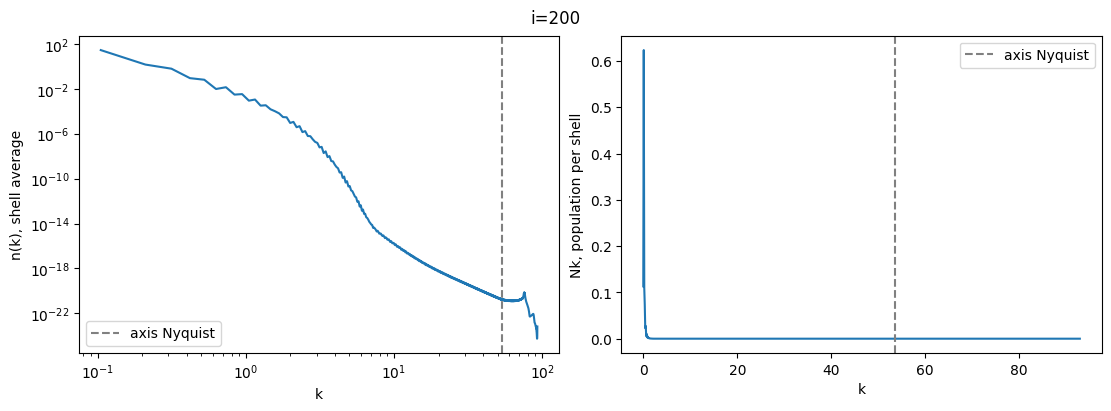

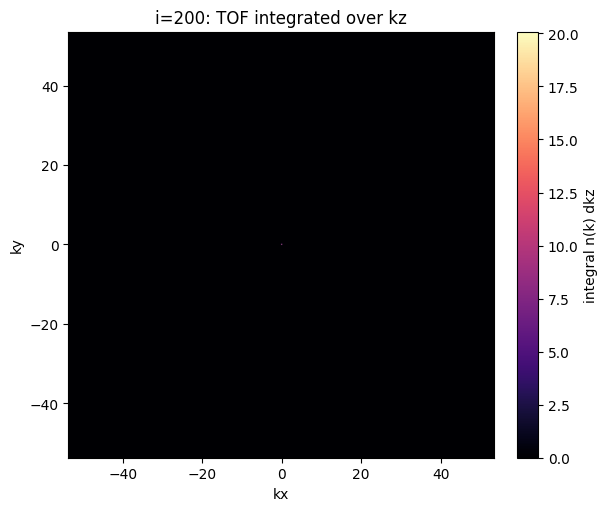

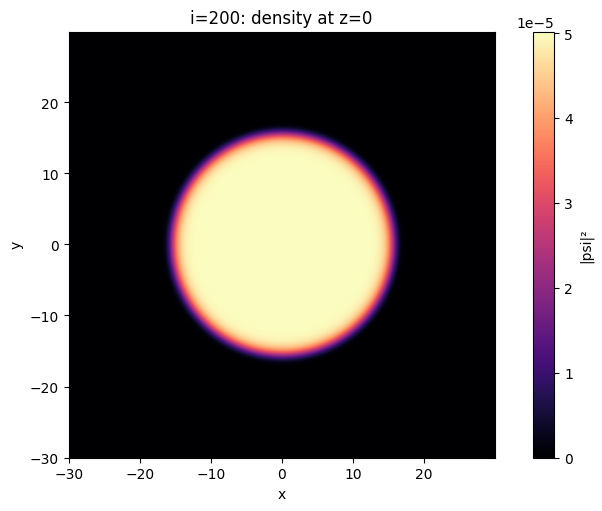

200/200: 261.34 ms/step, GPU used 56.44 GiB
Finished 200 steps in 76.13 s; final norm=1


In [6]:
print(f"Allocating {N_grids}³ arrays...",flush=True)
x_array,k_array=get_grids(N_grids,simulation_range)
psi=gaussian(x_array,sigma)
box=box_potential(x_array,R,L,wallthickness,U_D)
cp.cuda.get_current_stream().synchronize()

rows=[]
scalar_rows=[]
completed_steps=0
run_start=time.perf_counter()
for i in range(1,total_steps+1):
    wall_start=time.perf_counter()
    stages={}
    if warmup_steps<i<=warmup_steps+profile_steps:
        mode="profiled"
        psi,stages,gpu_ms=profiled_imaginary_step(psi,box,beta,k_array,img_dt,N_grids,x_array)
    else:
        mode="warmup" if i<=warmup_steps else "normal"
        step_start.record()
        psi=imaginary_step(psi,box,beta,k_array,img_dt,N_grids,x_array)
        step_end.record()
        step_end.synchronize()
        gpu_ms=cp.cuda.get_elapsed_time(step_start,step_end)
    step_wall_ms=1000*(time.perf_counter()-wall_start)
    completed_steps=i

    monitor_s=0.0
    if any(is_due(i,interval) for interval in monitor_intervals.values()):
        monitor_start=time.perf_counter()
        values=monitor(i,psi,k_array,x_array,**monitor_intervals)
        cp.cuda.get_current_stream().synchronize()
        monitor_s=time.perf_counter()-monitor_start
        if 'N' in values:
            scalar_rows.append(dict(i=i,N=values['N'],E_kin=values['E'],Lz=values['L']))

    free_now,total_now=cp.cuda.runtime.memGetInfo()
    rows.append(dict(i=i,mode=mode,gpu_ms=gpu_ms,step_wall_ms=step_wall_ms,
                     monitor_s=monitor_s,gpu_used_gib=(total_now-free_now)/GiB,
                     pool_reserved_gib=cp.get_default_memory_pool().total_bytes()/GiB,**stages))
    if i%progress_interval==0 or i==total_steps:
        print(f"{i}/{total_steps}: {gpu_ms:.2f} ms/step, GPU used {(total_now-free_now)/GiB:.2f} GiB",flush=True)

run_wall_s=time.perf_counter()-run_start
final_N=float(get_N(psi,x_array))
assert np.isfinite(final_N) and abs(final_N-1)<1e-8
print(f"Finished {completed_steps} steps in {run_wall_s:.2f} s; final norm={final_N:.12g}")


Ordinary steps: median 260.91 ms, mean 260.93 ms, p95 261.50 ms
Monitoring: 23.78 s total; saving is measured separately.
local_1_ms           24.675 ms  (  9.5% of profiled stages)
fft_ms               71.267 ms  ( 27.3% of profiled stages)
kinetic_ms           20.103 ms  (  7.7% of profiled stages)
ifft_ms              91.264 ms  ( 35.0% of profiled stages)
local_2_ms           24.646 ms  (  9.4% of profiled stages)
normalise_ms         29.128 ms  ( 11.2% of profiled stages)


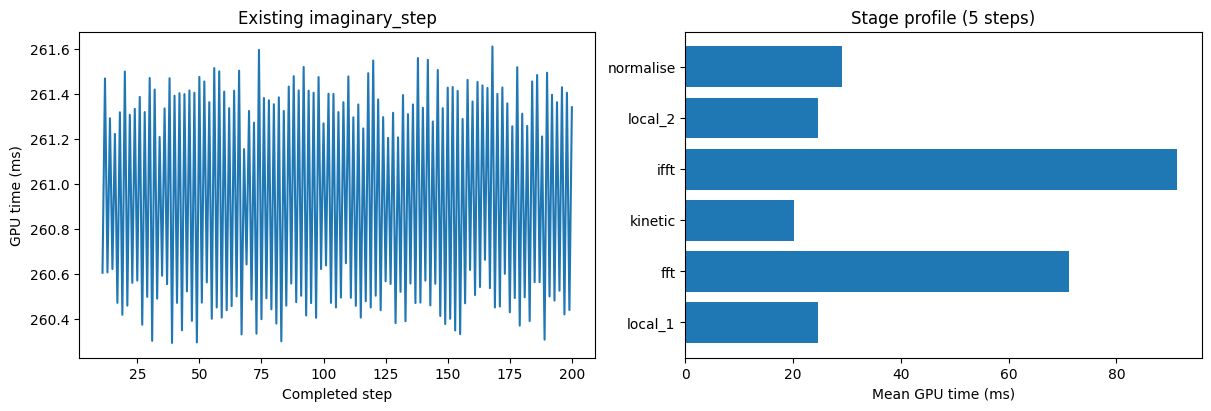

In [7]:
normal_rows=[row for row in rows if row['mode']=="normal"]
gpu_times=np.array([row['gpu_ms'] for row in normal_rows])
wall_times=np.array([row['step_wall_ms'] for row in normal_rows])
profile_rows=[row for row in rows if row['mode']=="profiled"]
stage_means={name:float(np.mean([row[name] for row in profile_rows])) for name in stage_names}
summary=dict(
    measured_steps=len(normal_rows),
    mean_gpu_ms=float(gpu_times.mean()),median_gpu_ms=float(np.median(gpu_times)),
    p95_gpu_ms=float(np.percentile(gpu_times,95)),mean_step_wall_ms=float(wall_times.mean()),
    evolution_wall_s=run_wall_s,monitor_wall_s=sum(row['monitor_s'] for row in rows),
    max_observed_gpu_used_gib=max(row['gpu_used_gib'] for row in rows),
    max_observed_pool_reserved_gib=max(row['pool_reserved_gib'] for row in rows),
    profiled_stage_means_ms=stage_means,
)
print(f"Ordinary steps: median {summary['median_gpu_ms']:.2f} ms, mean {summary['mean_gpu_ms']:.2f} ms, p95 {summary['p95_gpu_ms']:.2f} ms")
print(f"Monitoring: {summary['monitor_wall_s']:.2f} s total; saving is measured separately.")
for name,value in stage_means.items():
    print(f"{name:16s} {value:10.3f} ms  ({100*value/sum(stage_means.values()):5.1f}% of profiled stages)")

fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
axes[0].plot([row['i'] for row in normal_rows],gpu_times)
axes[0].set(xlabel="Completed step",ylabel="GPU time (ms)",title="Existing imaginary_step")
axes[1].barh([name.removesuffix('_ms') for name in stage_names],list(stage_means.values()))
axes[1].set(xlabel="Mean GPU time (ms)",title=f"Stage profile ({profile_steps} steps)")
plt.show()
plt.close(fig)


## Save the final state and benchmark results

This cell runs only after all requested steps finish. It writes the final state
in slabs, then copies the files to `MyDrive/GPE_simulator/benchmark_results/<run_id>`.
Allow space and transfer time for the 16 GiB state at N=1024. The accompanying axes,
parameters, source hashes, timings, and scalar history describe this preparation;
they are not a general checkpoint/restart format.


In [8]:
if completed_steps!=total_steps:
    raise RuntimeError("Finish the evolution cell before saving psi_final.")
LOCAL_RUN.mkdir(parents=True,exist_ok=True)
save_start=time.perf_counter()
export(completed_steps,psi,k_array,x_array,psi_interval=completed_steps,
       nk_interval=0,N_interval=0,output_dir=LOCAL_RUN)
(LOCAL_RUN/f"psi_{completed_steps:08d}.npy").replace(LOCAL_RUN/"psi_final.npy")
(LOCAL_RUN/f"psi_{completed_steps:08d}_grid.npz").replace(LOCAL_RUN/"psi_final_grid.npz")
summary['final_save_local_s']=time.perf_counter()-save_start

with (LOCAL_RUN/"step_timings.csv").open("w",newline="") as file:
    fields=["i","mode","gpu_ms","step_wall_ms","monitor_s","gpu_used_gib","pool_reserved_gib",*stage_names]
    writer=csv.DictWriter(file,fieldnames=fields)
    writer.writeheader()
    writer.writerows(rows)
with (LOCAL_RUN/"monitor_scalars.csv").open("w",newline="") as file:
    writer=csv.DictWriter(file,fieldnames=["i","N","E_kin","Lz"])
    writer.writeheader()
    writer.writerows(scalar_rows)

metadata=dict(
    run_id=run_id,gpu=gpu_name,cupy=cp.__version__,numpy=np.__version__,python=sys.version,
    cuda_runtime=cp.cuda.runtime.runtimeGetVersion(),cuda_driver=cp.cuda.runtime.driverGetVersion(),
    N_grids=N_grids,simulation_range=simulation_range,R=R,L=L,wallthickness=wallthickness,
    U_D=U_D,img_dt=img_dt,N_atom=N_atom,a_bohr=a,beta=beta,sigma=sigma,dtype=str(psi.dtype),
    completed_steps=completed_steps,imaginary_time=completed_steps*img_dt,final_norm=final_N,
    warmup_steps=warmup_steps,profile_steps=profile_steps,monitor_intervals=monitor_intervals,
    source_sha256={path.name:hashlib.sha256(path.read_bytes()).hexdigest()
                   for path in sorted((LOCAL_PROJECT/"gpe").iterdir()) if path.suffix in (".py",".cuh")},
    benchmark=summary,
)
(LOCAL_RUN/"run_metadata.json").write_text(json.dumps(metadata,indent=2)+"\n")

print(f"Local final save: {summary['final_save_local_s']:.2f} s. Copying results to Drive...",flush=True)
DRIVE_RUN.mkdir(parents=True,exist_ok=True)
copy_start=time.perf_counter()
for path in LOCAL_RUN.iterdir():
    if path.is_file():
        shutil.copy2(path,DRIVE_RUN/path.name)
print(f"Drive copy: {time.perf_counter()-copy_start:.2f} s")
print(f"Saved final state: {DRIVE_RUN/'psi_final.npy'}")


Local final save: 52.56 s. Copying results to Drive...
Drive copy: 56.18 s
Saved final state: /content/drive/MyDrive/GPE_simulator/benchmark_results/20261010T095235Z_N1024/psi_final.npy
